In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/naukri_com-job_sample.csv")
print(df.shape)
df.head()

(22000, 14)


,company,education,experience,industry,jobdescription,jobid,joblocation_address,jobtitle,numberofpositions,payrate,postdate,site_name,skills,uniq_id
0,MM Media Pvt Ltd,UG: B.Tech/B.E. - Any Specialization PG:Any Po...,0 - 1 yrs,Media / Entertainment / Internet,Job Description Send me Jobs like this Quali...,210516002263,Chennai,Walkin Data Entry Operator (night Shift),NaN,"1,50,000 - 2,25,000 P.A",2016-05-21 19:30:00 +0000,NaN,ITES,43b19632647068535437c774b6ca6cf8
1,find live infotech,UG: B.Tech/B.E. - Any Specialization PG:MBA/PG...,0 - 0 yrs,Advertising / PR / MR / Event Management,Job Description Send me Jobs like this Quali...,210516002391,Chennai,Work Based Onhome Based Part Time.,60.0,"1,50,000 - 2,50,000 P.A. 20000",2016-05-21 19:30:00 +0000,NaN,Marketing,d4c72325e57f89f364812b5ed5a795f0
2,Softtech Career Infosystem Pvt. Ltd,UG: Any Graduate - Any Specialization PG:Any P...,4 - 8 yrs,IT-Software / Software Services,Job Description Send me Jobs like this - as ...,101016900534,Bengaluru,Pl/sql Developer - SQL,NaN,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,IT Software - Application Programming,c47df6f4cfdf5b46f1fd713ba61b9eba
3,Onboard HRServices LLP,UG: Any Graduate - Any Specialization PG:CA Do...,11 - 15 yrs,Banking / Financial Services / Broking,Job Description Send me Jobs like this - Inv...,81016900536,"Mumbai, Bengaluru, Kolkata, Chennai, Coimbator...",Manager/ad/partner - Indirect Tax - CA,NaN,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,Accounts,115d28f140f694dd1cc61c53d03c66ae
4,Spire Technologies and Solutions Pvt. Ltd.,UG: B.Tech/B.E. - Any Specialization PG:Any Po...,6 - 8 yrs,IT-Software / Software Services,Job Description Send me Jobs like this Pleas...,120916002122,Bengaluru,JAVA Technical Lead (6-8 yrs) -,4.0,Not Disclosed by Recruiter,2016-10-13 16:20:55 +0000,NaN,IT Software - Application Programming,a12553fc03bc7bcced8b1bb8963f97b4


In [2]:
missing = df.isna().sum()
missing_percent = (missing / len(df) * 100).round(1).sort_values(ascending = False)

print(missing_percent)

site_name              81.9
numberofpositions      79.7
education               9.1
skills                  2.4
joblocation_address     2.3
payrate                 0.4
postdate                0.1
jobid                   0.0
industry                0.0
experience              0.0
company                 0.0
jobdescription          0.0
jobtitle                0.0
uniq_id                 0.0
dtype: float64


In [3]:
df_clean = df.drop(columns=["site_name", "numberofpositions"])
print(df_clean.shape)

(22000, 12)


In [4]:
print("jobid repeats:", df_clean["jobid"].duplicated().sum())
print("uniq_id repeats:", df_clean["uniq_id"].duplicated().sum())
print("fully duplicates:", df_clean.duplicated().sum())
content_only = df_clean.drop(columns=["jobid", "uniq_id"])
print("same content, different ids:", content_only.duplicated().sum())

jobid repeats: 90
uniq_id repeats: 0
fully duplicates: 0
same content, different ids: 1


In [5]:
content_columns = list(df_clean.columns)
content_columns.remove("jobid")
content_columns.remove("uniq_id")

df_clean = df_clean.drop_duplicates(subset=content_columns)
print(df_clean.shape)

(21999, 12)


In [6]:
repeated = df_clean[df_clean["jobid"].duplicated(keep=False)]
repeated = repeated.sort_values("jobid")
repeated[["jobid", "company", "jobtitle", "joblocation_address"]].head(10)

,jobid,company,jobtitle,joblocation_address
3350,10415500139,Just Dial,City Manager,"Hyderabad / Secunderabad , Mumbai , Noida"
16351,10415500139,Just Dial,City Manager,"Hyderabad / Secunderabad , Mumbai , Noida"
16677,10615500995,Avenues India Pvt. Ltd.,Marketing Executive,"Bengaluru/Bangalore , Chennai , Hyderabad / Se..."
3605,10615500995,Avenues India Pvt. Ltd.,Marketing Executive,"Bengaluru/Bangalore , Chennai , Hyderabad / Se..."
16757,10615505211,Fountainhead Digital | Digital Marketing Agency,Visualiser,Mumbai
15266,10615505211,Fountainhead Digital | Digital Marketing Agency,Visualiser,Mumbai
15268,10815500097,Aarav Infotech,Marketing Executive,Mumbai
16361,10815500097,Aarav Infotech,Marketing Executive,Mumbai
16822,10815500151,Resultrix,Search Engine Optimization Expert – SEO,"Delhi , Mumbai"
15267,10815500151,Resultrix,Search Engine Optimization Expert – SEO,"Delhi , Mumbai"


In [7]:
different_count = {}

for column in content_columns:
    values_per_job = repeated.groupby("jobid")[column].nunique(dropna=False)
    jobs_that_differ = (values_per_job > 1).sum()
    different_count[column] = jobs_that_differ

result = pd.Series(different_count)
result = result.sort_values(ascending=False)
print(result)

postdate               90
joblocation_address    32
jobdescription         30
education              29
company                 5
jobtitle                2
payrate                 2
industry                1
experience              0
skills                  0
dtype: int64


In [8]:
df_clean["postdate"] = pd.to_datetime(df_clean["postdate"], errors="coerce", utc=True)
df_clean = df_clean.sort_values("postdate")
df_clean = df_clean.drop_duplicates(subset="jobid", keep="last")
print(df_clean.shape)

(21909, 12)


In [9]:
industry_counts = df_clean["industry"].value_counts()
print(industry_counts.head(10))

industry
IT-Software / Software Services                  9184
Education / Teaching / Training                  1319
BPO / Call Centre / ITES                         1242
Banking / Financial Services / Broking           1231
Recruitment / Staffing                           1127
Internet / Ecommerce                              735
Pharma / Biotech / Clinical Research              520
Medical / Healthcare / Hospitals                  489
Automobile / Auto Anciliary / Auto Components     476
Construction / Engineering / Cement / Metals      448
Name: count, dtype: int64


In [10]:
industry_percent = df_clean["industry"].value_counts(normalize=True)
industry_percent = (industry_percent * 100).round(1)
print(industry_percent.head(10))

industry
IT-Software / Software Services                  41.9
Education / Teaching / Training                   6.0
BPO / Call Centre / ITES                          5.7
Banking / Financial Services / Broking            5.6
Recruitment / Staffing                            5.1
Internet / Ecommerce                              3.4
Pharma / Biotech / Clinical Research              2.4
Medical / Healthcare / Hospitals                  2.2
Automobile / Auto Anciliary / Auto Components     2.2
Construction / Engineering / Cement / Metals      2.0
Name: proportion, dtype: float64


In [11]:
print(df_clean["skills"].value_counts().head(10))

skills
IT Software - Application Programming    5968
Sales                                    2871
ITES                                     1622
Teaching                                 1091
HR                                        927
Marketing                                 865
Accounts                                  855
Production                                662
Medical                                   416
Financial Services                        410
Name: count, dtype: int64


In [12]:
pd.set_option("display.max_colwidth", None)
print(df_clean["jobdescription"].iloc[5])

Job Description   Send me Jobs like this Advertisement Number: I-50/2013-2014 Employee Type: Faculty Division: All Academic Divisions Application Last Date: Monday, May 1, 2017 Experience : - A minimum of six years teaching/research/professional experience of which 3 years should be at the level of Assistant Professor, Senior Scientific Officer/Senior Design Engineer in a research organization or industry as on the date of application. The candidate should have demonstrated adequate experience of independent research in terms of guidance of M.Tech. and Ph.D. students, publications in reputed journals and conferences, patents, laboratory/course development and/or other recognized relevant professional activities. PAY BAND : - PB-4 (Rs.37400-67000) with Academic Grade Pay of Rs.9,500/- p.m. For Direct recruits, minimum pay in the PB-4 to be fixed at Rs.42,800/- p.m. 1. Allowances as admissible to Central Government employees apply. 2. A Cumulative Professional Development Allowance of Rs

In [13]:
print(df_clean["postdate"].min())
print(df_clean["postdate"].max())
years = df_clean["postdate"].dt.year
print(years.value_counts().sort_index())

2015-01-24 19:48:31+00:00
2017-01-11 21:00:00+00:00
postdate
2015.0     5610
2016.0    16102
2017.0      174
Name: count, dtype: int64


In [14]:
clean_text = df_clean["jobdescription"].str.lower()
clean_text = clean_text.str.replace("send me jobs like this", "", regex=False)

In [15]:
skills_list = ["excel", "sql", "python", "communication", "tally",
               "sales", "accounting", "teaching", "customer service", "marketing"]

skill_counts = {}

for skill in skills_list:
    pattern = r"\b" + skill + r"s?\b"
    found = clean_text.str.contains(pattern, na=False)
    skill_counts[skill] = found.sum()

result = pd.Series(skill_counts)
result = result.sort_values(ascending=False)
print(result)

communication       8693
sales               4858
marketing           3555
sql                 2326
customer service    2199
teaching            1466
excel               1331
accounting           892
python               610
tally                158
dtype: int64


In [16]:
top_industries = df_clean["industry"].value_counts().head(5).index

results = {}

for industry in top_industries:
    rows = clean_text[df_clean["industry"] == industry]
    shares = {}

    for skill in skills_list:
        pattern = r"\b" + skill + r"s?\b"
        found = rows.str.contains(pattern, na=False)
        shares[skill] = round(found.mean() * 100, 1)

    results[industry] = shares

table = pd.DataFrame(results)
table

,IT-Software / Software Services,Education / Teaching / Training,BPO / Call Centre / ITES,Banking / Financial Services / Broking,Recruitment / Staffing
excel,5.4,1.9,8.9,14.3,5.9
sql,19.4,0.4,2.5,11.7,6.8
python,4.7,0.3,0.5,2.7,1.6
communication,41.9,17.2,53.0,44.6,43.7
tally,0.3,0.2,0.0,1.1,0.8
sales,14.5,8.8,16.2,41.7,23.4
accounting,2.1,1.4,5.3,8.7,2.6
teaching,0.5,100.0,0.6,0.4,1.2
customer service,4.6,2.6,78.3,11.2,6.2
marketing,12.8,7.2,9.7,15.8,11.4


In [17]:
education_rows = df_clean[df_clean["industry"] == "Education / Teaching / Training"]
sample_text = education_rows["jobdescription"].iloc[0]
position = sample_text.lower().find("functional area")
print(position)
print(sample_text[position - 200 : position + 300])

1443
n/sites/default/files/jobs/2014-08/AdvtI50Nov13.pdf http://www.iitb.ac.in/sites/default/files/jobs/2014-09/Infosheet11Sep2014.pdf Last Apply Date: 2017-05-01 Industry: Education / Teaching / Training Functional Area: Teaching , Education , Training , Counselling Desired Candidate Profile Please refer to the Job description above Company Profile: Indian Institute of Technology Bombay Download PPT Photo 1   View Contact Details


In [18]:
import textwrap
print(textwrap.fill(sample_text[position - 200 : position + 300], 90))

n/sites/default/files/jobs/2014-08/AdvtI50Nov13.pdf
http://www.iitb.ac.in/sites/default/files/jobs/2014-09/Infosheet11Sep2014.pdf Last Apply
Date: 2017-05-01 Industry: Education / Teaching / Training Functional Area: Teaching ,
Education , Training , Counselling Desired Candidate Profile Please refer to the Job
description above Company Profile: Indian Institute of Technology Bombay Download PPT
Photo 1   View Contact Details


In [19]:
education_text = clean_text[df_clean["industry"] == "Education / Teaching / Training"]
print(education_text.str.contains("functional area").mean())

1.0


In [20]:
real_text = clean_text.str.replace(r"(?s)industry:.*?desired candidate profile", " ", regex=True)
print("rows still containing the label:", real_text.str.contains("functional area:").sum())

rows still containing the label: 17


In [21]:
education_real = real_text[df_clean["industry"] == "Education / Teaching / Training"]
print(education_real.str.contains("functional area").mean())
print(education_real.str.contains(r"\bteaching\b").mean())

0.002274450341167551
0.5405610310841547


In [22]:
skill_counts = {}

for skill in skills_list:
    pattern = r"\b" + skill + r"s?\b"
    found = real_text.str.contains(pattern, na=False)
    skill_counts[skill] = found.sum()

result = pd.Series(skill_counts)
result = result.sort_values(ascending=False)
print(result)

communication       8553
sales               4018
marketing           2998
sql                 2195
excel               1310
customer service     822
teaching             787
accounting           613
python               590
tally                136
dtype: int64


In [23]:
top_industries = df_clean["industry"].value_counts().head(5).index

results = {}

for industry in top_industries:
    rows = real_text[df_clean["industry"] == industry]
    shares = {}

    for skill in skills_list:
        pattern = r"\b" + skill + r"s?\b"
        found = rows.str.contains(pattern, na=False)
        shares[skill] = round(found.mean() * 100, 1)

    results[industry] = shares

table = pd.DataFrame(results)
table

,IT-Software / Software Services,Education / Teaching / Training,BPO / Call Centre / ITES,Banking / Financial Services / Broking,Recruitment / Staffing
excel,5.3,1.9,8.7,14.1,5.9
sql,18.1,0.4,2.4,11.5,6.4
python,4.5,0.2,0.5,2.7,1.6
communication,41.6,16.5,51.9,44.4,43.1
tally,0.3,0.2,0.0,0.9,0.8
sales,12.8,7.2,11.1,29.8,17.7
accounting,1.9,0.9,4.8,7.1,2.4
teaching,0.3,54.1,0.3,0.0,0.5
customer service,2.4,0.5,16.8,5.3,2.6
marketing,11.6,6.6,6.4,12.8,10.0


The scraped descriptions contain a website footer with the industry and functional-area labels. This made some skills look universal (for example, "teaching" appeared in 100% of Education postings). I removed that block before counting. "Teaching" now appears in 54% of Education postings.

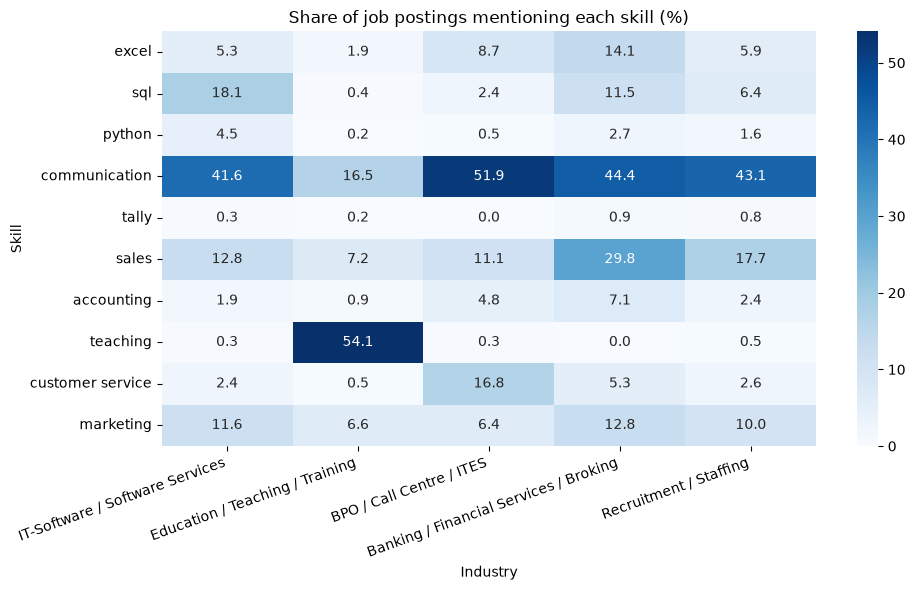

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(table, annot=True, fmt=".1f", cmap="Blues")
plt.title("Share of job postings mentioning each skill (%)")
plt.ylabel("Skill")
plt.xlabel("Industry")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

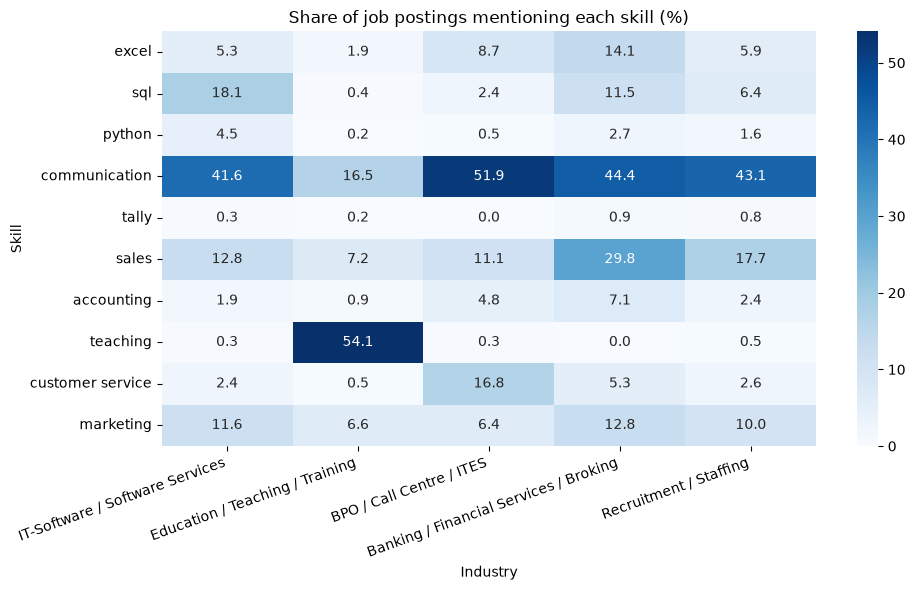

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(10, 6))
sns.heatmap(table, annot=True, fmt=".1f", cmap="Blues")
plt.title("Share of job postings mentioning each skill (%)")
plt.ylabel("Skill")
plt.xlabel("Industry")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/skills_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()